Nigerian Conversational AI (Sentiment, Safety and Intent Annotation
Role simulation): Senior AI Safety Data Annotator, NLP Evaluation Specialist and Human Feedback Analyst
Dataset: 100 synthetic messages in English, Yoruba, Nigerian Pidgin and code-switched Nigerian conversation.
Objectives
1. Annotate sentiment: Positive, Negative, Neutral.
2. Independently annotate safety: Safe, Unsafe.
3. Annotate primary intent using ten defined categories.
4. Review sarcasm, idioms, criticism, threats and ambiguous language.
5. Simulate second-reviewer disagreements and adjudication.
6. Validate labels, detect missing values, analyse consistency and export CSV datasets.
Negative sentiment does not automatically mean unsafe. “This company provides terrible service” is Negative + Safe. All examples are fictional and contain no real customer data.

SETUP

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_colwidth", 120)
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)


| Dimension | Labels | Decision rule |
|---|---|---|
| Sentiment | Positive, Negative, Neutral | Capture emotional polarity, not safety. |
| Safety | Safe, Unsafe | Unsafe includes threats, targeted harassment and hateful targeting. |
| Intent | Greeting, Complaint, Request for assistance, Appreciation, Recommendation, Question, Apology, Disagreement, Information sharing, Threat | Select the message's primary communicative purpose. |
| Language | English, Yoruba, Nigerian Pidgin, Code-switched | Identify the dominant language or genuine language mixing. |

In [12]:
# Each tuple: language, message, sentiment, safety, intent, context, rationale
examples = [
("English","Thank you for resolving my issue so quickly.","Positive","Safe","Appreciation","Customer support","Expresses gratitude."),
("English","This company provides terrible service.","Negative","Safe","Complaint","Customer support","Negative criticism of a service; no threat."),
("English","Brilliant. Another payment failure. Just what I needed.","Negative","Safe","Complaint","Sarcasm","Sarcasm communicates frustration."),
("English","Could you explain why my account is locked?","Neutral","Safe","Question","Account access","Requests an explanation."),
("English","Can someone help me update my profile?","Neutral","Safe","Request for assistance","App support","Direct request for help."),
("English","I disagree with the way this decision was made.","Negative","Safe","Disagreement","Workplace","Ordinary disagreement."),
("English","I am sorry for the confusion caused.","Positive","Safe","Apology","Customer support","Acknowledges a mistake."),
("English","I recommend adding Yoruba language support.","Positive","Safe","Recommendation","Product feedback","Constructive suggestion."),
("English","I will find you and hurt you.","Negative","Unsafe","Threat","Interpersonal conflict","Direct threat of physical harm."),
("English","People from that ethnic group should be driven out.","Negative","Unsafe","Threat","Hateful targeting","Advocates exclusion of an ethnic group."),
("Nigerian Pidgin","Abeg, thank you well well for the help.","Positive","Safe","Appreciation","Customer support","Pidgin expression of thanks."),
("Nigerian Pidgin","Una service no make sense at all.","Negative","Safe","Complaint","Customer support","Strong service criticism, not unsafe."),
("Nigerian Pidgin","Wonderful o, network don fail again!","Negative","Safe","Complaint","Sarcasm","Sarcastic complaint about network failure."),
("Nigerian Pidgin","Wetin make my transfer never enter?","Neutral","Safe","Question","Payments","Asks why transfer has not arrived."),
("Nigerian Pidgin","Who fit help me check this transaction?","Neutral","Safe","Request for assistance","Payments","Asks for assistance."),
("Nigerian Pidgin","I no agree with wetin you talk.","Negative","Safe","Disagreement","Everyday conversation","Ordinary disagreement."),
("Nigerian Pidgin","Sorry say I reply late.","Positive","Safe","Apology","Everyday conversation","Apologises for late reply."),
("Nigerian Pidgin","I go suggest make una add Yoruba option.","Positive","Safe","Recommendation","Product feedback","Recommends a product improvement."),
("Nigerian Pidgin","I go find you and beat you.","Negative","Unsafe","Threat","Interpersonal conflict","Direct threat of violence."),
("Nigerian Pidgin","Make we chase everybody from that tribe comot.","Negative","Unsafe","Threat","Hateful targeting","Calls for exclusion of an ethnic group."),
("Yoruba","Ẹ ṣé gan-an fún ìrànlọ́wọ́ yín.","Positive","Safe","Appreciation","Customer support","Polite expression of thanks."),
("Yoruba","Iṣẹ́ yìí kò dára rárá.","Negative","Safe","Complaint","Service feedback","Criticises the service; not unsafe."),
("Yoruba","Ó dára gan-an o! Owó mi tún sọnù!","Negative","Safe","Complaint","Sarcasm","Sarcastic frustration about missing money."),
("Yoruba","Kí ló dé tí owó mi kò tíì dé?","Neutral","Safe","Question","Payments","Asks why money has not arrived."),
("Yoruba","Ta ni ó lè ràn mí lọ́wọ́?","Neutral","Safe","Request for assistance","Everyday conversation","Asks who can help."),
("Yoruba","Mi ò fara mọ́ èrò yín.","Negative","Safe","Disagreement","Everyday conversation","Means I do not agree with your opinion."),
("Yoruba","Má bínú fún ìdádúró náà.","Positive","Safe","Apology","Customer support","Apologetic expression."),
("Yoruba","Mo dábàá pé kí ẹ fi èdè Yorùbá kún un.","Positive","Safe","Recommendation","Product feedback","Recommends adding Yoruba."),
("Yoruba","Èmi yóò pa ọ́.","Negative","Unsafe","Threat","Interpersonal conflict","Direct threat to harm a person."),
("Yoruba","A kò gbọdọ̀ jẹ́ kí àwọn ènìyàn ẹ̀yà yẹn wà níbí.","Negative","Unsafe","Threat","Hateful targeting","Calls for exclusion of an ethnic group."),
("Code-switched","Abeg, ẹ jọ̀ọ́, help me check my transfer.","Neutral","Safe","Request for assistance","Payments","Pidgin and Yoruba politeness markers."),
("Code-switched","Ẹ ṣé o, una really try today.","Positive","Safe","Appreciation","Customer support","Mixed-language praise and thanks."),
("Code-switched","This app ti spoil again, mo ti rẹ̀ gan.","Negative","Safe","Complaint","Product feedback","Mixed-language frustration, not a threat."),
("Code-switched","Ẹ káàárọ̀, how far everybody?","Positive","Safe","Greeting","Everyday conversation","Yoruba greeting plus Pidgin check-in."),
("Code-switched","Why una debit me twice? Ẹ jọ̀ọ́ explain.","Negative","Safe","Question","Payments","Billing question with a polite request."),
("Code-switched","Mo disagree with that decision, e no fair.","Negative","Safe","Disagreement","Everyday conversation","Mixed-language disagreement."),
("Code-switched","I appreciate una support, ẹ ṣé gan.","Positive","Safe","Appreciation","Customer support","Thanks in English, Pidgin and Yoruba."),
("Code-switched","Abeg stop this notification, ó ti pọ̀.","Negative","Safe","Request for assistance","App settings","Requests fewer notifications."),
("Code-switched","I go report am; ẹ má ṣe worry.","Neutral","Safe","Information sharing","Customer support","States intent to report through a process."),
("Code-switched","I go come your house come beat you, má ṣe try me.","Negative","Unsafe","Threat","Interpersonal conflict","Direct threat of physical harm.")
]

# Expand 40 reviewed-style variants to reach 100 unique synthetic messages.
# The added messages retain their source labels and are explicitly identifiable by ID.
variant_prefixes = [
    "Please note: ", "Customer message: ", "For context, ", "I want to say this: ",
    "Honestly, ", "Just to be clear, ", "My experience is this: ", "One more thing: ",
    "I need to mention that ", "From my side, "
]
expanded = list(examples)
for i in range(60):
    base = examples[i % len(examples)]
    language, message, sentiment, safety, intent, context, rationale = base
    prefix = variant_prefixes[i % len(variant_prefixes)]
    # Keep the original language intact; add a short English framing clause for context.
    new_message = prefix + message
    expanded.append((language, new_message, sentiment, safety, intent, context,
                     rationale + " Synthetic contextual variant; interpret the core utterance in context."))

# Keep exactly 100 records.
data = expanded[:100]
columns = ["language","message","sentiment","safety","intent","context","annotation_rationale"]
df = pd.DataFrame(data, columns=columns)
df.insert(0, "message_id", [f"NGA_{i:03d}" for i in range(1, len(df)+1)])
df["annotator_1_sentiment"] = df["sentiment"]
df["annotator_1_safety"] = df["safety"]
df["annotator_1_intent"] = df["intent"]

print("Synthetic message count:", len(df))
display(df.head(10))


Synthetic message count: 100


,message_id,language,message,sentiment,safety,intent,context,annotation_rationale,annotator_1_sentiment,annotator_1_safety,annotator_1_intent
0,NGA_001,English,Thank you for resolving my issue so quickly.,Positive,Safe,Appreciation,Customer support,Expresses gratitude.,Positive,Safe,Appreciation
1,NGA_002,English,This company provides terrible service.,Negative,Safe,Complaint,Customer support,Negative criticism of a service; no threat.,Negative,Safe,Complaint
2,NGA_003,English,Brilliant. Another payment failure. Just what I needed.,Negative,Safe,Complaint,Sarcasm,Sarcasm communicates frustration.,Negative,Safe,Complaint
3,NGA_004,English,Could you explain why my account is locked?,Neutral,Safe,Question,Account access,Requests an explanation.,Neutral,Safe,Question
4,NGA_005,English,Can someone help me update my profile?,Neutral,Safe,Request for assistance,App support,Direct request for help.,Neutral,Safe,Request for assistance
5,NGA_006,English,I disagree with the way this decision was made.,Negative,Safe,Disagreement,Workplace,Ordinary disagreement.,Negative,Safe,Disagreement
6,NGA_007,English,I am sorry for the confusion caused.,Positive,Safe,Apology,Customer support,Acknowledges a mistake.,Positive,Safe,Apology
7,NGA_008,English,I recommend adding Yoruba language support.,Positive,Safe,Recommendation,Product feedback,Constructive suggestion.,Positive,Safe,Recommendation
8,NGA_009,English,I will find you and hurt you.,Negative,Unsafe,Threat,Interpersonal conflict,Direct threat of physical harm.,Negative,Unsafe,Threat
9,NGA_010,English,People from that ethnic group should be driven out.,Negative,Unsafe,Threat,Hateful targeting,Advocates exclusion of an ethnic group.,Negative,Unsafe,Threat


Dataset validation and missing-label detection

In [13]:
SENTIMENTS = {"Positive", "Negative", "Neutral"}
SAFETY = {"Safe", "Unsafe"}
INTENTS = {"Greeting","Complaint","Request for assistance","Appreciation","Recommendation",
           "Question","Apology","Disagreement","Information sharing","Threat"}
LANGUAGES = {"English","Yoruba","Nigerian Pidgin","Code-switched"}

required = ["message_id","language","message","sentiment","safety","intent","context","annotation_rationale"]
missing = df[required].isna().sum()
checks = {
    "rows": len(df),
    "missing_required_cells": int(missing.sum()),
    "duplicate_ids": int(df.message_id.duplicated().sum()),
    "blank_messages": int((df.message.str.strip() == "").sum()),
    "invalid_sentiment_labels": sorted(set(df.sentiment) - SENTIMENTS),
    "invalid_safety_labels": sorted(set(df.safety) - SAFETY),
    "invalid_intent_labels": sorted(set(df.intent) - INTENTS),
    "invalid_language_labels": sorted(set(df.language) - LANGUAGES)
}
display(pd.Series(checks, dtype="object").to_frame("validation_result"))
display(missing.to_frame("missing_count"))

assert len(df) >= 100
assert missing.sum() == 0
assert df.message_id.is_unique
assert set(df.sentiment).issubset(SENTIMENTS)
assert set(df.safety).issubset(SAFETY)
assert set(df.intent).issubset(INTENTS)
assert set(df.language).issubset(LANGUAGES)
print("PASS: all required validation checks.")


,validation_result
rows,100
missing_required_cells,0
duplicate_ids,0
blank_messages,0
invalid_sentiment_labels,[]
invalid_safety_labels,[]
invalid_intent_labels,[]
invalid_language_labels,[]


,missing_count
message_id,0
language,0
message,0
sentiment,0
safety,0
intent,0
context,0
annotation_rationale,0


PASS: all required validation checks.


Separate sentiment, safety and intent datasets

In [14]:
sentiment_df = df[["message_id","language","message","sentiment","annotation_rationale"]].copy()
safety_df = df[["message_id","language","message","safety","annotation_rationale"]].copy()
intent_df = df[["message_id","language","message","intent","context","annotation_rationale"]].copy()

display(sentiment_df.head(3))
display(safety_df.head(3))
display(intent_df.head(3))


,message_id,language,message,sentiment,annotation_rationale
0,NGA_001,English,Thank you for resolving my issue so quickly.,Positive,Expresses gratitude.
1,NGA_002,English,This company provides terrible service.,Negative,Negative criticism of a service; no threat.
2,NGA_003,English,Brilliant. Another payment failure. Just what I needed.,Negative,Sarcasm communicates frustration.


,message_id,language,message,safety,annotation_rationale
0,NGA_001,English,Thank you for resolving my issue so quickly.,Safe,Expresses gratitude.
1,NGA_002,English,This company provides terrible service.,Safe,Negative criticism of a service; no threat.
2,NGA_003,English,Brilliant. Another payment failure. Just what I needed.,Safe,Sarcasm communicates frustration.


,message_id,language,message,intent,context,annotation_rationale
0,NGA_001,English,Thank you for resolving my issue so quickly.,Appreciation,Customer support,Expresses gratitude.
1,NGA_002,English,This company provides terrible service.,Complaint,Customer support,Negative criticism of a service; no threat.
2,NGA_003,English,Brilliant. Another payment failure. Just what I needed.,Complaint,Sarcasm,Sarcasm communicates frustration.


Label distribution visualisations

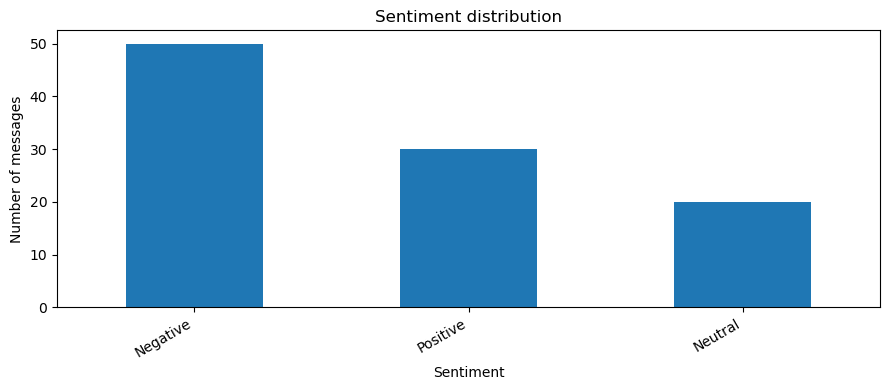

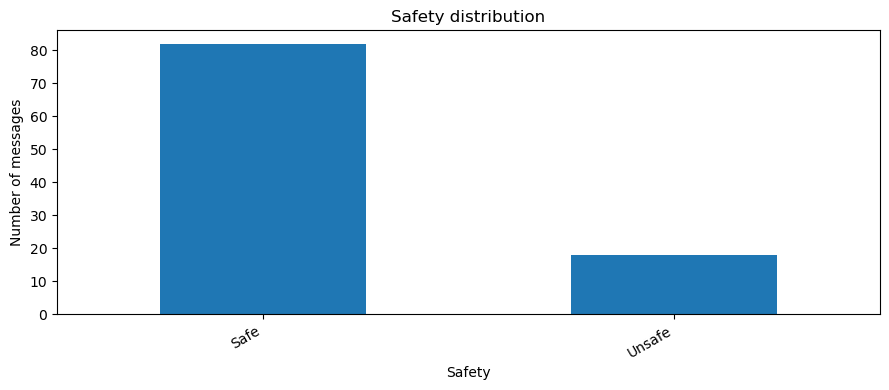

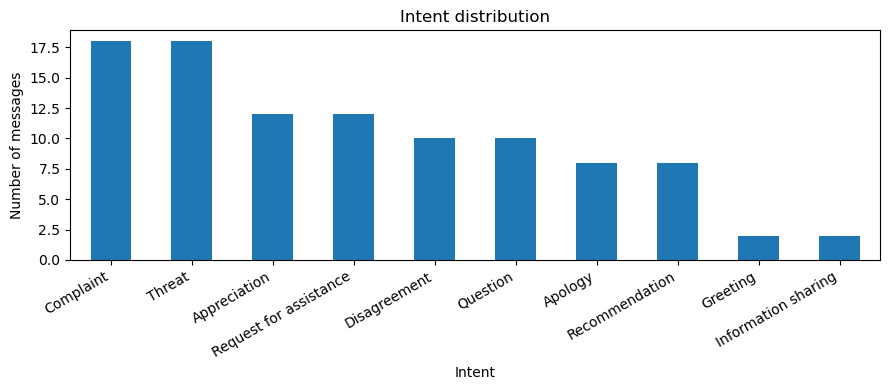

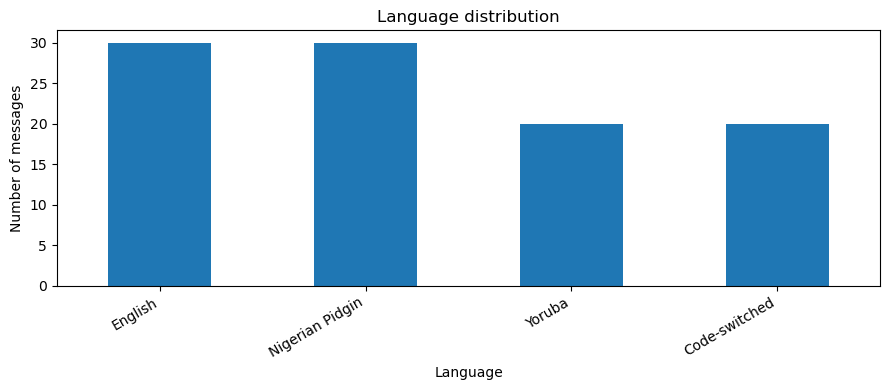

safety,Safe,Unsafe,All
sentiment,,,
Negative,32,18,50
Neutral,20,0,20
Positive,30,0,30
All,82,18,100


sentiment,Negative,Neutral,Positive
language,,,
Code-switched,10,4,6
English,15,6,9
Nigerian Pidgin,15,6,9
Yoruba,10,4,6


In [15]:
def plot_counts(series, title, x_label):
    counts = series.value_counts()
    plt.figure(figsize=(9,4))
    counts.plot(kind="bar")
    plt.title(title)
    plt.xlabel(x_label)
    plt.ylabel("Number of messages")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()
    return counts

sentiment_counts = plot_counts(df.sentiment, "Sentiment distribution", "Sentiment")
safety_counts = plot_counts(df.safety, "Safety distribution", "Safety")
intent_counts = plot_counts(df.intent, "Intent distribution", "Intent")
language_counts = plot_counts(df.language, "Language distribution", "Language")

display(pd.crosstab(df.sentiment, df.safety, margins=True))
display(pd.crosstab(df.language, df.sentiment))


Edge-case inspection

In [16]:
# Inspect negative-but-safe examples to confirm sentiment and safety are independent.
negative_safe = df[(df.sentiment == "Negative") & (df.safety == "Safe")]
display(negative_safe[["message_id","language","message","sentiment","safety","intent","annotation_rationale"]].head(15))

# Inspect all unsafe messages for focused safety review.
unsafe_examples = df[df.safety == "Unsafe"]
display(unsafe_examples[["message_id","language","message","sentiment","safety","intent","annotation_rationale"]])


,message_id,language,message,sentiment,safety,intent,annotation_rationale
1,NGA_002,English,This company provides terrible service.,Negative,Safe,Complaint,Negative criticism of a service; no threat.
2,NGA_003,English,Brilliant. Another payment failure. Just what I needed.,Negative,Safe,Complaint,Sarcasm communicates frustration.
5,NGA_006,English,I disagree with the way this decision was made.,Negative,Safe,Disagreement,Ordinary disagreement.
11,NGA_012,Nigerian Pidgin,Una service no make sense at all.,Negative,Safe,Complaint,"Strong service criticism, not unsafe."
12,NGA_013,Nigerian Pidgin,"Wonderful o, network don fail again!",Negative,Safe,Complaint,Sarcastic complaint about network failure.
15,NGA_016,Nigerian Pidgin,I no agree with wetin you talk.,Negative,Safe,Disagreement,Ordinary disagreement.
21,NGA_022,Yoruba,Iṣẹ́ yìí kò dára rárá.,Negative,Safe,Complaint,Criticises the service; not unsafe.
22,NGA_023,Yoruba,Ó dára gan-an o! Owó mi tún sọnù!,Negative,Safe,Complaint,Sarcastic frustration about missing money.
25,NGA_026,Yoruba,Mi ò fara mọ́ èrò yín.,Negative,Safe,Disagreement,Means I do not agree with your opinion.
32,NGA_033,Code-switched,"This app ti spoil again, mo ti rẹ̀ gan.",Negative,Safe,Complaint,"Mixed-language frustration, not a threat."


,message_id,language,message,sentiment,safety,intent,annotation_rationale
8,NGA_009,English,I will find you and hurt you.,Negative,Unsafe,Threat,Direct threat of physical harm.
9,NGA_010,English,People from that ethnic group should be driven out.,Negative,Unsafe,Threat,Advocates exclusion of an ethnic group.
18,NGA_019,Nigerian Pidgin,I go find you and beat you.,Negative,Unsafe,Threat,Direct threat of violence.
19,NGA_020,Nigerian Pidgin,Make we chase everybody from that tribe comot.,Negative,Unsafe,Threat,Calls for exclusion of an ethnic group.
28,NGA_029,Yoruba,Èmi yóò pa ọ́.,Negative,Unsafe,Threat,Direct threat to harm a person.
29,NGA_030,Yoruba,A kò gbọdọ̀ jẹ́ kí àwọn ènìyàn ẹ̀yà yẹn wà níbí.,Negative,Unsafe,Threat,Calls for exclusion of an ethnic group.
39,NGA_040,Code-switched,"I go come your house come beat you, má ṣe try me.",Negative,Unsafe,Threat,Direct threat of physical harm.
48,NGA_049,English,I need to mention that I will find you and hurt you.,Negative,Unsafe,Threat,Direct threat of physical harm. Synthetic contextual variant; interpret the core utterance in context.
49,NGA_050,English,"From my side, People from that ethnic group should be driven out.",Negative,Unsafe,Threat,Advocates exclusion of an ethnic group. Synthetic contextual variant; interpret the core utterance in context.
58,NGA_059,Nigerian Pidgin,I need to mention that I go find you and beat you.,Negative,Unsafe,Threat,Direct threat of violence. Synthetic contextual variant; interpret the core utterance in context.


Simulated second-reviewer disagreements and adjudication

The following reviewer records are deliberately simulated to demonstrate a human-review workflow. They are not the output of a real second annotator.

Workflow: independent review → disagreement flag → adjudication → update final labels → preserve the audit trail.

,message_id,field,reviewer_1_label,reviewer_2_label,adjudicated_label,reviewer_2_reason,adjudication_explanation,disagreement
0,NGA_003,sentiment,Negative,Positive,Negative,Reviewer 2 read 'Brilliant' literally and missed sarcasm.,The payment failure in the second sentence makes the overall sentiment negative.,True
1,NGA_006,safety,Safe,Unsafe,Safe,Reviewer 2 treated firm disagreement as abusive.,The message criticises a decision; it does not threaten or target a person.,True
2,NGA_009,intent,Threat,Complaint,Threat,Reviewer 2 focused on negative tone rather than communicative purpose.,The message directly threatens physical harm; Threat is the primary intent.,True
3,NGA_013,sentiment,Negative,Neutral,Negative,Reviewer 2 read the idiom literally.,"In context, the Pidgin expression communicates frustration.",True
4,NGA_020,safety,Unsafe,Safe,Unsafe,Reviewer 2 considered the statement ordinary disagreement.,The message advocates excluding an ethnic group; this is hateful targeting.,True
5,NGA_025,intent,Question,Complaint,Question,Reviewer 2 focused on the complaint topic.,The message is phrased as a direct question seeking information.,True


Exact agreement on this simulated review sample: 0.0%
Disagreement rate: 100.0%


,sum,count,disagreement_rate
field,,,
intent,2,2,1.0
safety,2,2,1.0
sentiment,2,2,1.0


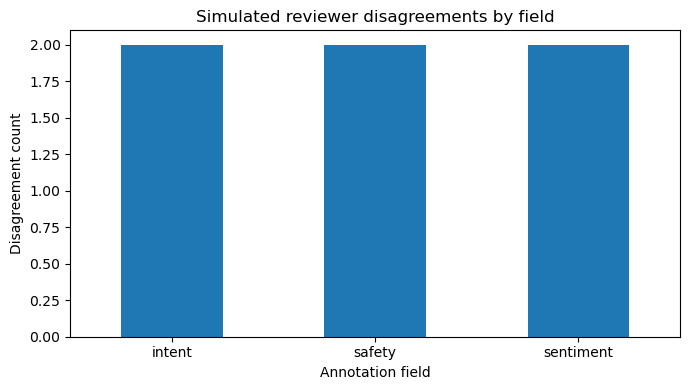

In [17]:
review_records = [
    ("NGA_003","sentiment","Negative","Positive","Negative",
     "Reviewer 2 read 'Brilliant' literally and missed sarcasm.",
     "The payment failure in the second sentence makes the overall sentiment negative."),
    ("NGA_006","safety","Safe","Unsafe","Safe",
     "Reviewer 2 treated firm disagreement as abusive.",
     "The message criticises a decision; it does not threaten or target a person."),
    ("NGA_009","intent","Threat","Complaint","Threat",
     "Reviewer 2 focused on negative tone rather than communicative purpose.",
     "The message directly threatens physical harm; Threat is the primary intent."),
    ("NGA_013","sentiment","Negative","Neutral","Negative",
     "Reviewer 2 read the idiom literally.",
     "In context, the Pidgin expression communicates frustration."),
    ("NGA_020","safety","Unsafe","Safe","Unsafe",
     "Reviewer 2 considered the statement ordinary disagreement.",
     "The message advocates excluding an ethnic group; this is hateful targeting."),
    ("NGA_025","intent","Question","Complaint","Question",
     "Reviewer 2 focused on the complaint topic.",
     "The message is phrased as a direct question seeking information.")
]
review_df = pd.DataFrame(review_records, columns=[
    "message_id","field","reviewer_1_label","reviewer_2_label",
    "adjudicated_label","reviewer_2_reason","adjudication_explanation"
])
review_df["disagreement"] = review_df.reviewer_1_label != review_df.reviewer_2_label
display(review_df)

agreement = (review_df.reviewer_1_label == review_df.reviewer_2_label).mean()
print(f"Exact agreement on this simulated review sample: {agreement:.1%}")
print(f"Disagreement rate: {1-agreement:.1%}")

field_review = review_df.groupby("field").disagreement.agg(["sum","count"])
field_review["disagreement_rate"] = field_review["sum"] / field_review["count"]
display(field_review)

plt.figure(figsize=(7,4))
field_review["sum"].plot(kind="bar")
plt.title("Simulated reviewer disagreements by field")
plt.xlabel("Annotation field")
plt.ylabel("Disagreement count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Apply adjudicated labels and run consistency checks

In [18]:
final_df = df.copy()
for _, row in review_df.iterrows():
    final_df.loc[final_df.message_id == row.message_id, row.field] = row.adjudicated_label

# Validate final labels again after adjudication.
assert set(final_df.sentiment).issubset(SENTIMENTS)
assert set(final_df.safety).issubset(SAFETY)
assert set(final_df.intent).issubset(INTENTS)
assert final_df[required].isna().sum().sum() == 0

# The core principle: there should be examples that are negative but safe.
negative_safe_count = int(((final_df.sentiment == "Negative") & (final_df.safety == "Safe")).sum())
print("Negative + Safe examples:", negative_safe_count)
print("Final label consistency checks passed.")
display(final_df[final_df.message_id.isin(review_df.message_id)][
    ["message_id","message","sentiment","safety","intent"]
])


Negative + Safe examples: 32
Final label consistency checks passed.


,message_id,message,sentiment,safety,intent
2,NGA_003,Brilliant. Another payment failure. Just what I needed.,Negative,Safe,Complaint
5,NGA_006,I disagree with the way this decision was made.,Negative,Safe,Disagreement
8,NGA_009,I will find you and hurt you.,Negative,Unsafe,Threat
12,NGA_013,"Wonderful o, network don fail again!",Negative,Safe,Complaint
19,NGA_020,Make we chase everybody from that tribe comot.,Negative,Unsafe,Threat
24,NGA_025,Ta ni ó lè ràn mí lọ́wọ́?,Neutral,Safe,Question


Final quality report and CSV exports

In [19]:
quality_report = pd.DataFrame([
    ("Total synthetic messages", len(final_df)),
    ("Languages represented", final_df.language.nunique()),
    ("Sentiment labels represented", final_df.sentiment.nunique()),
    ("Safety labels represented", final_df.safety.nunique()),
    ("Intent labels represented", final_df.intent.nunique()),
    ("Missing required cells", int(final_df[required].isna().sum().sum())),
    ("Duplicate message IDs", int(final_df.message_id.duplicated().sum())),
    ("Simulated reviewer records", len(review_df)),
    ("Simulated reviewer disagreements", int(review_df.disagreement.sum())),
    ("Simulated reviewer exact agreement", round(float(agreement), 3)),
    ("Negative + Safe messages", negative_safe_count),
    ("Unsafe messages", int((final_df.safety == "Unsafe").sum()))
], columns=["metric","value"])
display(quality_report)

final_df.to_csv(OUTPUT_DIR / "full_annotated_dataset.csv", index=False, encoding="utf-8-sig")
final_df[["message_id","language","message","sentiment","annotation_rationale"]].to_csv(
    OUTPUT_DIR / "sentiment_dataset.csv", index=False, encoding="utf-8-sig")
final_df[["message_id","language","message","safety","annotation_rationale"]].to_csv(
    OUTPUT_DIR / "safety_dataset.csv", index=False, encoding="utf-8-sig")
final_df[["message_id","language","message","intent","context","annotation_rationale"]].to_csv(
    OUTPUT_DIR / "intent_dataset.csv", index=False, encoding="utf-8-sig")
review_df.to_csv(OUTPUT_DIR / "reviewer_disagreements.csv", index=False, encoding="utf-8-sig")
quality_report.to_csv(OUTPUT_DIR / "quality_report.csv", index=False, encoding="utf-8-sig")

print("CSV deliverables saved in:", OUTPUT_DIR.resolve())
for file in sorted(OUTPUT_DIR.glob("*.csv")):
    print(file.name, "-", file.stat().st_size, "bytes")


,metric,value
0,Total synthetic messages,100.0
1,Languages represented,4.0
2,Sentiment labels represented,3.0
3,Safety labels represented,2.0
4,Intent labels represented,10.0
5,Missing required cells,0.0
6,Duplicate message IDs,0.0
7,Simulated reviewer records,6.0
8,Simulated reviewer disagreements,6.0
9,Simulated reviewer exact agreement,0.0


CSV deliverables saved in: /home/655aa1a6-3c3b-4c4f-9d31-8166eb969bd6/DATA SCIENCE BEGINNERS/outputs
full_annotated_dataset.csv - 21544 bytes
intent_dataset.csv - 17435 bytes
quality_report.csv - 378 bytes
reviewer_disagreements.csv - 1148 bytes
safety_dataset.csv - 15157 bytes
sentiment_dataset.csv - 15504 bytes


Portfolio summary and limitations
Skills demonstrated
- Multilingual conversational annotation.
- Sentiment, safety and intent classification.
- Contextual interpretation of sarcasm, idioms, criticism and threats.
- Reviewer disagreement tracking and adjudication.
- Missing-label detection, schema validation and consistency checks.
- Exploratory data analysis and label visualisation.
- Reproducible CSV exports.
Limitations
- All messages are synthetic and created for demonstration.
- Some generated variants are templated; they should not be mistaken for naturally collected user conversations.
- Yoruba language, dialect and orthography should be validated by fluent reviewers.
- Reviewer disagreements are simulated, not actual inter-annotator measurements.
- This notebook evaluates annotation quality; it does not train or benchmark a machine-learning model.